# 실습 2. MLP vs LSTM — 시계열의 순서 구조 학습

**목표**
- 시간별 교통량(합성 데이터)으로 다음 1시간 교통량을 예측
- MLP(윈도우를 펼쳐 입력)와 LSTM(순서대로 입력)의 구조 차이와 성능 비교
- 슬라이딩 윈도우, 시간 순 분할 등 시계열 전처리 절차 익히기

## 0. 환경 설정

In [9]:
!pip -q install koreanize-matplotlib

In [10]:
import koreanize_matplotlib   # 그래프 한글 표시 (import만 하면 자동 적용)
import numpy as np            # 배열·수치 계산
import torch                  # PyTorch 기본 패키지
import torch.nn as nn         # 신경망 레이어(Linear, LSTM 등)
from torch.utils.data import TensorDataset, DataLoader   # 텐서를 데이터셋으로 묶고 미니배치로 공급
import matplotlib.pyplot as plt                          # 시각화

# 난수 시드 고정 (numpy: 데이터 생성의 잡음, torch: 가중치 초기화) → 재현성 확보
np.random.seed(42); torch.manual_seed(42)

# GPU를 쓸 수 있으면 "cuda", 아니면 "cpu"
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cuda


## 1. 합성 교통량 데이터 생성
- 120일 × 24시간 = 2,880개 관측치
- 출근(8시)·퇴근(18시) 첨두, 주말 감소, 완만한 추세, 무작위 잡음 포함
- 실제 데이터(예: 서울시 교통량 API)로 교체해도 이후 코드는 그대로 사용 가능

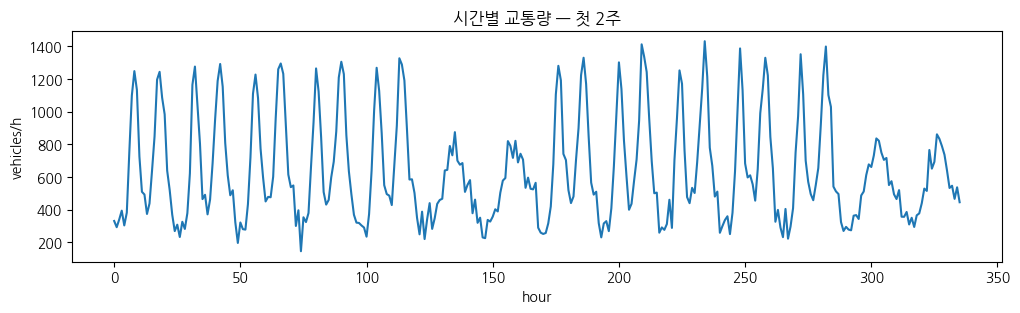

In [11]:
# ===== 시간 축 만들기 =====
days = 120
hours = np.arange(days * 24)     # 0, 1, 2, ..., 2879 (관측 시점 번호)
hod = hours % 24                 # 시각 (hour of day: 0~23)
dow = (hours // 24) % 7          # 요일 (day of week: 0~6, 5·6 = 주말)

# ===== 교통량 패턴 구성 요소 =====
# 가우시안(종 모양) 함수 exp(-(x-중심)^2 / 폭)으로 첨두 시간대 표현
am_peak = np.exp(-((hod - 8) ** 2) / 4)     # 오전 8시 출근 첨두 (폭 좁음)
pm_peak = np.exp(-((hod - 18) ** 2) / 6)    # 오후 6시 퇴근 첨두 (조금 더 넓게 퍼짐)
# 기본 교통량: 300대 + 낮 시간대(5시~29시) 사인 곡선, clip(0)으로 음수 부분 제거 → 새벽엔 300대
base = 300 + 200 * np.sin(np.pi * (hod - 5) / 24).clip(0)
weekday = (dow < 5).astype(float)          # 평일=1.0, 주말=0.0

# ===== 모든 요소 합치기 =====
traffic = (base
           + weekday * (900 * am_peak + 800 * pm_peak)               # 평일에만 출퇴근 첨두
           + (1 - weekday) * 300 * np.exp(-((hod - 14) ** 2) / 20)    # 주말엔 오후 2시 무렵 완만한 봉우리
           + 0.5 * hours / 24                       # 추세: 하루에 0.5대씩 증가 (120일간 +60대)
           + np.random.normal(0, 60, len(hours)))   # 잡음: 평균 0, 표준편차 60대
traffic = traffic.clip(0).astype(np.float32)        # 음수 교통량 방지 + PyTorch 기본 자료형(float32)으로

# ===== 첫 2주(336시간) 그려 보기 =====
plt.figure(figsize=(12, 3))
plt.plot(traffic[:24*14])
plt.title("시간별 교통량 — 첫 2주"); plt.xlabel("hour"); plt.ylabel("vehicles/h")
plt.show()

## 2. 슬라이딩 윈도우 구성
- 입력: 과거 `WINDOW`시간 교통량 → 출력: 다음 1시간 교통량
- **시간 순서대로** 학습/테스트 분할 (무작위 분할 시 미래 정보 누출)
- 정규화 통계량은 학습 구간에서만 계산

In [12]:
WINDOW = 48                         # 과거 48시간(2일)을 보고 다음 1시간을 예측
split = int(len(traffic) * 0.8)     # 앞 80%(2,304시간)는 학습, 뒤 20%는 테스트

# ===== 정규화: 학습 구간의 평균·표준편차만 사용 =====
# 테스트 구간 통계까지 쓰면 "미래 정보"가 학습에 새어 들어감 (data leakage)
mean, std = traffic[:split].mean(), traffic[:split].std()
series = (traffic - mean) / std     # 평균 0, 표준편차 1 근처로 맞춰 학습 안정화

# ===== 슬라이딩 윈도우 =====
# 예) window=3, s=[a,b,c,d,e] → X=[[a,b,c],[b,c,d]], y=[d,e]
def make_windows(s, window):
    X = np.stack([s[i:i+window] for i in range(len(s) - window)])   # 한 칸씩 밀며 window 길이로 자르기
    y = s[window:]                                                  # 각 윈도우 바로 다음 값이 정답
    return X, y

X, y = make_windows(series, WINDOW)

# ===== 시간 순서대로 분할 (섞지 않음!) =====
# 정답(y)의 시점이 split보다 앞이면 학습, 뒤면 테스트가 되도록 split - WINDOW에서 자름
n_train = split - WINDOW
X_train, y_train = X[:n_train], y[:n_train]
X_test,  y_test  = X[n_train:], y[n_train:]
print("train:", X_train.shape, " test:", X_test.shape)   # (샘플 수, 윈도우 길이)

# 학습 데이터는 DataLoader로 미니배치 공급 (윈도우끼리 섞는 건 OK: 각 윈도우 내부 순서는 유지됨)
train_loader = DataLoader(TensorDataset(torch.tensor(X_train), torch.tensor(y_train)),
                          batch_size=64, shuffle=True)
# 테스트는 한 번에 통째로 예측하므로 미리 텐서로 만들어 장치에 올려 둠
X_test_t = torch.tensor(X_test).to(device)

train: (2256, 48)  test: (576, 48)


## 3. 학습·평가 함수

In [13]:
# ===== 모델 학습 함수 =====
def train_model(model, epochs=20, lr=1e-3):
    model = model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()              # 회귀 문제 → 평균제곱오차 손실 (분류의 cross_entropy 대신)
    for ep in range(epochs):
        model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            loss = loss_fn(model(xb), yb)                   # 예측값과 실제값의 오차
            opt.zero_grad(); loss.backward(); opt.step()    # 기울기 초기화 → 역전파 → 가중치 업데이트
        if (ep + 1) % 5 == 0:                               # 5 epoch마다 테스트 성능 출력
            print(f"  epoch {ep+1}: test RMSE = {rmse(model):.1f} vehicles/h")
    return model

# ===== 테스트 구간 예측 =====
@torch.no_grad()                        # 예측만 하므로 기울기 계산 끔
def predict(model):
    model.eval()
    # 모델은 정규화된 값을 출력하므로 "× std + mean"으로 원래 단위(대/시간)로 되돌림
    return model(X_test_t).cpu().numpy() * std + mean

# ===== RMSE (평균제곱근오차) =====
# 예측이 실제값에서 평균적으로 몇 대 정도 벗어나는지 → 작을수록 좋음
def rmse(model):
    pred = predict(model)
    true = y_test * std + mean          # 정답도 원래 단위로 복원
    return float(np.sqrt(np.mean((pred - true) ** 2)))

## 4. 기준 모델: MLP
- 48시간 윈도우를 48차원 벡터로 입력 → 시점 간 순서를 구조적으로 알지 못함

In [14]:
# ===== 기준 모델: MLP =====
class MLP(nn.Module):
    def __init__(self, window):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(window, 64), nn.ReLU(),   # 48개 시점 값을 한꺼번에 입력 → 64
            nn.Linear(64, 32), nn.ReLU(),       # 64 → 32
            nn.Linear(32, 1)                    # 32 → 1 (다음 1시간 교통량)
        )
        # 주의: MLP에게 48개 입력은 그냥 48개의 "칸"일 뿐,
        #       어느 칸이 과거이고 어느 칸이 최근인지 구조적으로 알지 못함
    def forward(self, x):            # x: (batch, window)
        return self.net(x).squeeze(-1)   # (batch, 1) → (batch,) 정답 y와 모양 맞추기

mlp = train_model(MLP(WINDOW))

  epoch 5: test RMSE = 91.5 vehicles/h
  epoch 10: test RMSE = 84.9 vehicles/h
  epoch 15: test RMSE = 79.8 vehicles/h
  epoch 20: test RMSE = 75.9 vehicles/h


## 5. LSTM
- 입력 형태: `(batch, window)` → `(batch, window, 1)` (시점별 특성 1개)
- 시점을 하나씩 읽으며 은닉 상태(hidden state)·셀 상태(cell state)를 갱신
- 마지막 시점의 은닉 상태로 다음 값 예측

In [15]:
# ===== LSTM 모델 =====
class LSTMModel(nn.Module):
    def __init__(self, hidden=32, layers=1):
        super().__init__()
        # input_size=1 : 각 시점마다 들어오는 특성 수 (교통량 1개)
        # hidden_size  : 은닉 상태(기억) 벡터의 크기
        # batch_first=True : 입력 모양을 (batch, 시점, 특성) 순서로 사용
        self.lstm = nn.LSTM(input_size=1, hidden_size=hidden,
                            num_layers=layers, batch_first=True)
        self.fc = nn.Linear(hidden, 1)      # 마지막 은닉 상태(32) → 예측값(1)

    def forward(self, x):            # x: (batch, window)
        # unsqueeze(-1): (batch, 48) → (batch, 48, 1)  시점마다 특성 1개라는 차원 추가
        # out: 모든 시점의 은닉 상태, h: 마지막 은닉 상태, c: 마지막 셀 상태(장기 기억)
        out, (h, c) = self.lstm(x.unsqueeze(-1))   # out: (batch, window, hidden)
        # out[:, -1, :] : 48개 시점을 모두 읽은 뒤의 마지막 은닉 상태 → 과거 정보가 요약돼 있음
        return self.fc(out[:, -1, :]).squeeze(-1)  # 마지막 시점

lstm = train_model(LSTMModel())

  epoch 5: test RMSE = 122.7 vehicles/h
  epoch 10: test RMSE = 94.7 vehicles/h
  epoch 15: test RMSE = 91.6 vehicles/h
  epoch 20: test RMSE = 89.6 vehicles/h


## 6. 결과 비교

MLP : params= 5,249  RMSE=75.9
LSTM: params= 4,513  RMSE=89.6


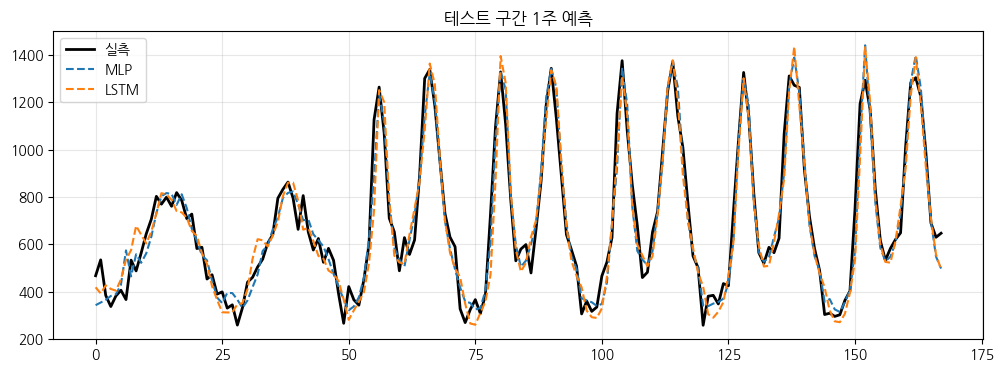

In [16]:
# 파라미터 수 세는 한 줄짜리 함수
count = lambda m: sum(p.numel() for p in m.parameters())
print(f"MLP : params={count(mlp):>6,}  RMSE={rmse(mlp):.1f}")    # :>6, → 오른쪽 정렬 6칸 + 천 단위 콤마
print(f"LSTM: params={count(lstm):>6,}  RMSE={rmse(lstm):.1f}")

# ===== 테스트 구간 첫 1주(168시간) 예측 그래프 =====
true = y_test * std + mean           # 실측값 (원래 단위)
idx = slice(0, 24 * 7)               # 처음 168시간만 잘라서 보기
plt.figure(figsize=(12, 4))
plt.plot(true[idx], "k", lw=2, label="실측")           # 검은 굵은 실선
plt.plot(predict(mlp)[idx], "--", label="MLP")         # 점선
plt.plot(predict(lstm)[idx], "--", label="LSTM")
plt.title("테스트 구간 1주 예측"); plt.legend(); plt.grid(alpha=.3)
plt.show()

## 7. 추가 과제
1. `nn.LSTM`을 `nn.GRU`로 바꾸면 성능·파라미터 수는? (힌트: GRU는 `(h)`만 반환)
2. `WINDOW`를 12, 24, 168(1주)로 바꿔 보라. 어느 모델이 긴 윈도우에 더 민감한가?
3. 요일·시각을 추가 입력 특성으로 넣어 보라 (`input_size` 변경).
4. (토론) LSTM은 긴 시퀀스에서 왜 여전히 한계가 있는가? → 다음 실습의 Attention으로 연결

### 추가 과제 1. LSTM → GRU로 바꾸기
- GRU는 LSTM의 게이트 4개(입력·망각·출력·후보)를 3개(리셋·업데이트·후보)로 줄이고, **셀 상태 없이 은닉 상태 하나만** 사용
- 그래서 `nn.GRU`는 `out, (h, c)`가 아니라 `out, h`만 반환
- 파라미터 수 예상: 게이트당 `hidden×(input+hidden) + 2×hidden` = 32×33 + 64 = 1,120개
  - LSTM: 4 × 1,120 + fc 33 = **4,513개**
  - GRU : 3 × 1,120 + fc 33 = **3,393개** (약 25% 감소)

In [17]:
# ===== GRU 모델 =====
class GRUModel(nn.Module):
    def __init__(self, hidden=32, layers=1):
        super().__init__()
        self.gru = nn.GRU(input_size=1, hidden_size=hidden,
                          num_layers=layers, batch_first=True)   # nn.LSTM → nn.GRU (인자는 동일)
        self.fc = nn.Linear(hidden, 1)

    def forward(self, x):                          # x: (batch, window)
        out, h = self.gru(x.unsqueeze(-1))         # GRU는 셀 상태 c가 없어 (h)만 반환
        return self.fc(out[:, -1, :]).squeeze(-1)  # 마지막 시점의 은닉 상태로 예측

torch.manual_seed(42)                              # 공정한 비교를 위해 초기화 시드 고정
gru = train_model(GRUModel())

print(f"\n{'모델':<6}{'파라미터':>10}{'RMSE':>10}")
for name, m in [("MLP", mlp), ("LSTM", lstm), ("GRU", gru)]:
    print(f"{name:<6}{count(m):>10,}{rmse(m):>10.1f}")

# ============================================================
# [실행 결과 해설] (T4 기준, 실행마다 조금씩 다를 수 있음)
# ============================================================
# 모델    파라미터    RMSE
# MLP       5,249     75.9
# LSTM      4,513     89.6
# GRU       3,393     88.8
#
# - 파라미터: GRU는 게이트가 3개라 LSTM(4개)보다 정확히 3/4 수준 (4,480 → 3,360, fc 33개 별도)
# - 성능: GRU(88.8)와 LSTM(89.6)이 거의 같음 → 이 정도 길이·난이도의 시계열에서는
#         셀 상태(c)가 따로 없어도 충분. 더 가볍고 빠른 GRU가 실용적인 선택
# - 둘 다 MLP(75.9)보다 나쁨: 20 epoch로는 순환 모델이 아직 덜 수렴했고(RMSE가 계속 내려가는 중),
#   MLP는 "24시간 전 같은 시각" 값을 가중치로 바로 참조할 수 있어 주기성이 강한 데이터에 유리
# - 참고: 잡음 표준편차가 60대이므로 RMSE 60 근처가 사실상 도달 가능한 하한선

  epoch 5: test RMSE = 116.9 vehicles/h
  epoch 10: test RMSE = 102.1 vehicles/h
  epoch 15: test RMSE = 93.5 vehicles/h
  epoch 20: test RMSE = 88.8 vehicles/h

모델          파라미터      RMSE
MLP        5,249      75.9
LSTM       4,513      89.6
GRU        3,393      88.8


### 추가 과제 2. WINDOW 길이 바꿔 보기 (12, 24, 48, 168)
- 윈도우가 바뀌면 `X_train`, `train_loader`, `X_test_t` 등을 모두 다시 만들어야 함 → `set_window()` 함수로 묶음
- 테스트 정답(`y_test`)은 항상 `split` 이후 시점이라 **윈도우가 달라도 같은 구간으로 평가**됨 → 공정한 비교 가능

===== WINDOW = 12 (train (2292, 12), test (576, 12)) =====
 [MLP]
  epoch 5: test RMSE = 92.4 vehicles/h
  epoch 10: test RMSE = 89.0 vehicles/h
  epoch 15: test RMSE = 88.3 vehicles/h
  epoch 20: test RMSE = 86.1 vehicles/h
 [LSTM]
  epoch 5: test RMSE = 120.7 vehicles/h
  epoch 10: test RMSE = 97.8 vehicles/h
  epoch 15: test RMSE = 92.9 vehicles/h
  epoch 20: test RMSE = 89.4 vehicles/h
===== WINDOW = 24 (train (2280, 24), test (576, 24)) =====
 [MLP]
  epoch 5: test RMSE = 94.0 vehicles/h
  epoch 10: test RMSE = 85.4 vehicles/h
  epoch 15: test RMSE = 82.9 vehicles/h
  epoch 20: test RMSE = 82.4 vehicles/h
 [LSTM]
  epoch 5: test RMSE = 117.9 vehicles/h
  epoch 10: test RMSE = 97.0 vehicles/h
  epoch 15: test RMSE = 88.4 vehicles/h
  epoch 20: test RMSE = 88.5 vehicles/h
===== WINDOW = 48 (train (2256, 48), test (576, 48)) =====
 [MLP]
  epoch 5: test RMSE = 91.5 vehicles/h
  epoch 10: test RMSE = 84.9 vehicles/h
  epoch 15: test RMSE = 79.8 vehicles/h
  epoch 20: test RMSE = 75.9 

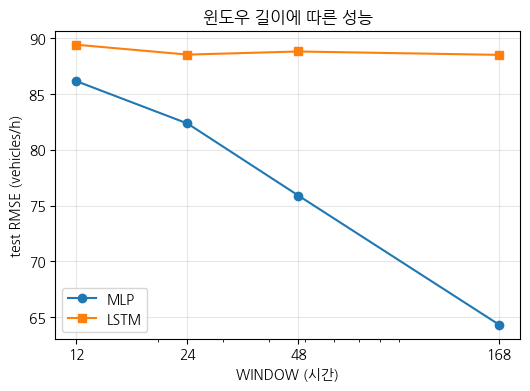

In [18]:
# ===== 윈도우 길이에 맞춰 데이터를 다시 만드는 함수 =====
def set_window(window):
    # train_model / predict / rmse 함수가 전역 변수를 쓰므로 global로 갱신
    global X_train, y_train, X_test, y_test, train_loader, X_test_t
    X, y = make_windows(series, window)
    n_train = split - window
    X_train, y_train = X[:n_train], y[:n_train]
    X_test,  y_test  = X[n_train:], y[n_train:]
    train_loader = DataLoader(TensorDataset(torch.tensor(X_train), torch.tensor(y_train)),
                              batch_size=64, shuffle=True)
    X_test_t = torch.tensor(X_test).to(device)

results = {}                                       # {window: (MLP RMSE, LSTM RMSE)}
for w in [12, 24, 48, 168]:
    set_window(w)
    print(f"===== WINDOW = {w} (train {X_train.shape}, test {X_test.shape}) =====")
    torch.manual_seed(42); print(" [MLP]");  m = train_model(MLP(w))     # MLP는 입력 크기가 window에 따라 바뀜
    torch.manual_seed(42); print(" [LSTM]"); l = train_model(LSTMModel()) # LSTM은 window와 무관하게 구조 동일
    results[w] = (rmse(m), rmse(l))

set_window(WINDOW)                                 # 원래 설정(48)으로 되돌리기 (이후 셀에 영향 없도록)

# ===== 결과 표 + 그래프 =====
print(f"\n{'WINDOW':>8}{'MLP RMSE':>12}{'LSTM RMSE':>12}")
for w, (a, b) in results.items():
    print(f"{w:>8}{a:>12.1f}{b:>12.1f}")

ws = list(results)
plt.figure(figsize=(6, 4))
plt.plot(ws, [results[w][0] for w in ws], "o-", label="MLP")
plt.plot(ws, [results[w][1] for w in ws], "s-", label="LSTM")
plt.xscale("log"); plt.xticks(ws, ws)              # 12~168로 범위가 넓어 로그 축 사용
plt.xlabel("WINDOW (시간)"); plt.ylabel("test RMSE (vehicles/h)")
plt.title("윈도우 길이에 따른 성능"); plt.legend(); plt.grid(alpha=.3)
plt.show()

# ============================================================
# [실행 결과 해설]
# ============================================================
# WINDOW   MLP RMSE   LSTM RMSE
#     12       86.1        89.4
#     24       82.4        88.5
#     48       75.9        88.8
#    168       64.3        88.5
#
# Q. 어느 모델이 긴 윈도우에 더 민감한가?  → MLP
# - MLP: 12 → 168로 늘리자 RMSE가 86.1 → 64.3으로 크게 개선 (잡음 하한 60에 근접)
#   · 168시간(1주) 윈도우에는 "어제 같은 시각", "지난주 같은 요일·시각" 값이 들어 있고,
#     MLP는 각 입력 칸에 가중치가 따로 있어서 그 값을 직접 꺼내 쓸 수 있음
#   · 대가: 입력 크기에 비례해 파라미터 증가 (48 → 5,249개, 168 → 12,929개)
# - LSTM: 윈도우를 14배로 늘려도 88~89로 거의 변화 없음 (파라미터 수도 4,513개로 고정)
#   · 정보를 한 시점씩 은닉 상태(32차원)에 눌러 담으며 전달하기 때문에
#     수십~백여 단계 전 정보는 희미해지고, 사실상 최근 몇 시간 위주로 예측
#   · 즉 "긴 입력을 줘도 그만큼 활용하지 못한다" → 추가 과제 4의 한계와 직결

### 추가 과제 3. 요일·시각을 추가 입력 특성으로 넣기
- 시각(0~23)과 요일(0~6)은 **순환형** 변수 → 23시와 0시가 가깝다는 걸 알려 주려고 `sin`, `cos`로 변환
- 주말 여부(0/1)도 추가 → 시점마다 특성 6개: `[교통량, sin(시각), cos(시각), sin(요일), cos(요일), 주말]`
- 입력 모양: `(batch, window)` → `(batch, window, 6)`
  - LSTM: `input_size=1` → `input_size=6`
  - MLP : `window` → `window × 6` 개로 펼쳐서 입력

In [19]:
# ===== 시점별 특성 6개 만들기 =====
feats = np.stack([
    series,                                  # 정규화된 교통량
    np.sin(2 * np.pi * hod / 24),            # 시각 → 원 위의 좌표 (23시와 0시가 가까워짐)
    np.cos(2 * np.pi * hod / 24),
    np.sin(2 * np.pi * dow / 7),             # 요일도 같은 방식 (일요일과 월요일이 가까워짐)
    np.cos(2 * np.pi * dow / 7),
    (dow >= 5).astype(float),                # 주말이면 1
], axis=1).astype(np.float32)                # (2880, 6)
N_FEAT = feats.shape[1]

# ===== 다변량 슬라이딩 윈도우 =====
Xf = np.stack([feats[i:i+WINDOW] for i in range(len(feats) - WINDOW)])   # (샘플, 48, 6)
yf = series[WINDOW:]                                                     # 정답은 그대로 교통량
n_train = split - WINDOW
train_loader = DataLoader(TensorDataset(torch.tensor(Xf[:n_train]), torch.tensor(yf[:n_train])),
                          batch_size=64, shuffle=True)
X_test_t = torch.tensor(Xf[n_train:]).to(device)    # y_test는 이전과 동일한 값이라 그대로 사용
print("입력 모양:", Xf.shape)

# ===== 다변량 MLP: (batch, 48, 6) → 288개로 펼쳐서 입력 =====
class MLPFeat(nn.Module):
    def __init__(self, window, n_feat):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),                                   # (batch, 48, 6) → (batch, 288)
            nn.Linear(window * n_feat, 64), nn.ReLU(),
            nn.Linear(64, 32), nn.ReLU(),
            nn.Linear(32, 1)
        )
    def forward(self, x):
        return self.net(x).squeeze(-1)

# ===== 다변량 LSTM: input_size만 6으로 =====
class LSTMFeat(nn.Module):
    def __init__(self, n_feat, hidden=32):
        super().__init__()
        self.lstm = nn.LSTM(input_size=n_feat, hidden_size=hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 1)
    def forward(self, x):                           # x: (batch, window, n_feat) → 이미 3차원이라 unsqueeze 불필요
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :]).squeeze(-1)

torch.manual_seed(42); print("[MLP + 시간 특성]");  mlp_f  = train_model(MLPFeat(WINDOW, N_FEAT))
torch.manual_seed(42); print("[LSTM + 시간 특성]"); lstm_f = train_model(LSTMFeat(N_FEAT))
mlp_f_rmse, lstm_f_rmse = rmse(mlp_f), rmse(lstm_f)

set_window(WINDOW)                                  # 단변량 데이터로 되돌리기
print(f"\n{'모델':<8}{'교통량만':>10}{'+시간 특성':>12}")
print(f"{'MLP':<8}{rmse(mlp):>10.1f}{mlp_f_rmse:>12.1f}")
print(f"{'LSTM':<8}{rmse(lstm):>10.1f}{lstm_f_rmse:>12.1f}")

# ============================================================
# [실행 결과 해설]
# ============================================================
# 모델    교통량만   +시간 특성
# MLP        75.9        66.4   (-9.5)
# LSTM       89.6        67.2   (-22.4)
#
# - 두 모델 모두 개선, 특히 LSTM이 크게 좋아져 MLP와 거의 같은 수준이 됨
# - 이유: 교통량은 "몇 시인지·주말인지"가 거의 결정함 (출퇴근 첨두, 주말 패턴)
#   · 교통량만 줄 때는 모델이 과거 값의 모양을 보고 지금이 몇 시인지 스스로 추론해야 함
#   · 시각·요일을 직접 주면 그 추론이 필요 없어짐
#   · LSTM은 긴 과거를 잘 기억하지 못해 이 추론이 특히 어려웠으므로 이득이 더 큼
# - sin/cos 변환 덕분에 23시↔0시, 일요일↔월요일이 연속적으로 이어짐
#   (숫자 0~23을 그대로 넣으면 23과 0이 가장 멀게 인식됨)
# - 실무 시사점: 모델 구조를 바꾸는 것보다 도메인 지식에 기반한 특성(feature) 설계가
#   더 큰 효과를 낼 때가 많음 (공휴일, 날씨, 행사 정보 등도 같은 방식으로 추가 가능)

입력 모양: (2832, 48, 6)
[MLP + 시간 특성]
  epoch 5: test RMSE = 67.9 vehicles/h
  epoch 10: test RMSE = 70.1 vehicles/h
  epoch 15: test RMSE = 67.2 vehicles/h
  epoch 20: test RMSE = 66.4 vehicles/h
[LSTM + 시간 특성]
  epoch 5: test RMSE = 83.0 vehicles/h
  epoch 10: test RMSE = 78.0 vehicles/h
  epoch 15: test RMSE = 73.0 vehicles/h
  epoch 20: test RMSE = 67.2 vehicles/h

모델            교통량만      +시간 특성
MLP           75.9        66.4
LSTM          89.6        67.2


### 추가 과제 4. (토론) LSTM은 긴 시퀀스에서 왜 여전히 한계가 있는가?

**1. 정보가 한 단계씩 "릴레이"로 전달됨**
- LSTM은 `t-168` 시점의 정보를 지금까지 가져오려면 168번의 게이트를 모두 통과시켜야 해요.
- 게이트 덕분에 기본 RNN보다 기울기 소실이 훨씬 덜하지만, 완전히 없어지진 않아서 실제로 잘 기억하는 범위는 수십~백여 단계 정도예요.
- **실습 근거**: 과제 2에서 윈도우를 12 → 168로 늘려도 LSTM의 RMSE는 89.4 → 88.5로 거의 그대로였어요. 반면 각 시점에 직접 접근하는 MLP는 86.1 → 64.3으로 크게 좋아졌어요.

**2. 고정 크기 은닉 상태라는 병목(bottleneck)**
- 입력이 12시간이든 168시간이든 결국 **32차원 벡터 하나**(`out[:, -1, :]`)로 요약해서 예측해요.
- 시퀀스가 길어질수록 담아야 할 정보는 많아지는데 그릇 크기는 그대로라서, 오래된 정보부터 덮어써져요.

**3. 필요한 과거 시점을 골라서 볼 수 없음**
- 교통량 예측에 가장 중요한 건 "어제 같은 시각(t-24)", "지난주 같은 시각(t-168)" 같은 특정 시점이에요.
- LSTM은 이 시점들만 콕 집어 볼 방법이 없고, 모든 정보를 순서대로 섞어 가며 읽을 수밖에 없어요.

**4. 순차 계산이라 병렬화가 어려움**
- `t` 시점을 계산하려면 `t-1`이 끝나야 해서 GPU를 충분히 활용하지 못해요. 시퀀스가 길수록 학습이 느려져요.

**→ Attention으로 연결**
- Attention은 현재 시점이 과거의 **모든 시점을 한 번에 직접** 보고, 시점마다 "얼마나 중요한지" 가중치(attention score)를 계산해 가중합을 만들어요.
  - 1번 해결: 168시간 전 정보도 거리 1로 바로 연결됨
  - 2번 해결: 하나의 벡터로 압축하지 않고 필요한 시점을 그때그때 참조
  - 3번 해결: t-24, t-168에 높은 가중치를 주는 식으로 스스로 학습 (가중치를 시각화하면 해석도 가능)
  - 4번 해결: 모든 시점을 행렬 연산으로 동시에 계산 → 병렬화 가능 (Transformer의 핵심)
- 과제 2에서 MLP가 긴 윈도우에서 잘한 것도 "각 시점에 직접 접근"했기 때문이에요. Attention은 이 장점을 순서 정보·유연한 길이 처리와 함께 갖춘 구조라고 볼 수 있어요.